## Imports

In [1]:
import pandas as pd 
from sklearn.model_selection import train_test_split
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.metrics import accuracy_score, r2_score, f1_score
from sklearn.preprocessing import StandardScaler
import torchmetrics
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
GLOBAL_LEARNING_RATE = 1e-3
GLOBAL_EPOCHS = 25 

c:\Users\LOQ\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda


## Processing Data

In [2]:
df = pd.read_csv("EngineFaultDB_Final.csv")
X = df.drop(['Fault'], axis=1).values
y = df['Fault'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
df.head()   

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
0,0,3.549,1.889,7.428,5.227,1192.769,3.057,11.720,24.901,0.460,196.089,14.356,1.080,1.047,15.385
1,0,3.559,1.899,7.646,5.327,1145.191,2.914,11.276,25.030,0.478,196.283,14.492,1.107,1.083,15.926
2,0,3.539,1.899,7.578,5.100,1208.505,2.976,11.926,24.213,0.464,200.367,14.443,1.099,1.072,15.754
3,0,3.519,1.889,7.371,5.255,1164.127,2.908,11.786,24.407,0.471,195.345,13.853,1.076,1.006,14.787
4,0,3.549,1.879,7.405,5.177,1172.032,2.898,12.169,24.875,0.468,194.979,13.752,1.060,0.984,14.470


In [4]:
df.describe()

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
count,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000
mean,1.482187,1.832515,1.395269,286.691705,5.657126,2398.053774,4.497634,8.939794,51.688740,1.932430,188.446083,13.035230,0.585910,0.963907,14.169408
std,1.149430,0.837786,0.906950,378.774917,7.684147,932.008680,2.221497,3.154110,20.140345,1.988789,111.047015,1.046567,0.223713,0.065973,0.969802
min,0.000000,0.453000,0.382000,2.580000,0.465000,1066.452000,1.917000,5.187000,22.757000,0.421000,1.787000,8.649000,0.203000,0.695000,10.210000
25%,0.000000,1.217000,0.901000,76.848500,0.994000,1830.200500,2.981000,6.573000,39.412000,0.641000,158.803000,12.842000,0.415000,0.937000,13.780000
50%,2.000000,1.543000,1.013000,92.500000,2.398000,2105.588000,3.824000,8.068000,45.393000,1.129000,178.265000,13.242000,0.533000,0.977000,14.365000
75%,3.000000,1.940000,1.258000,257.989500,4.696000,2761.373500,5.144500,9.924000,59.508000,2.455000,203.678000,13.639000,0.789000,1.008000,14.823000
max,3.000000,4.547000,4.048000,1537.118000,33.946000,5013.402000,14.810000,20.043000,107.539000,10.132000,975.657000,15.129000,1.151000,1.149000,16.893000


In [3]:
'''
We also need to define feature configurations to be used in our experiments
Reference for features:
[MAP, TPS, Force, Power, RPM, Consumption L/H, Consumption L/100KM, Speed, CO, HC, CO2, O2, Lambda, AFR]   

CA: [MAP, TPS, Force, Power, RPM] 
CB: [MAP, RPM, O2, Lambda, AFR] 
CC: [CO, HC, CO2, O2, Lambda]
CD = [MAP, TPS, RPM, O2, Lambda, AFR, CO2]

C1: [MAP, TPS, RPM, O2, Lambda]
C2: [MAP, TPS, RPM, CO2, AFR]
C3: [MAP, RPM, CO2, O2, AFR]

C4: [TPS, RPM, CO2, O2, Lambda, AFR]

'''

C0 = [1,1,1,1,1,1,1,1,1,1,1,1,1,1] # Used for control experiments, C0 C0 

C1  = [1,1,1,0,1,0,0,0,0,0,0,1,0,0]  # [MAP, TPS, Force, RPM, O2]
C2  = [1,1,0,1,1,0,0,0,0,0,1,0,0,0]  # [MAP, TPS, Power, RPM, CO2]
C3  = [1,0,0,0,1,0,0,0,0,0,1,1,0,1]  # [MAP, RPM, CO2, O2, AFR]
C4  = [0,0,1,1,1,0,0,1,0,0,0,0,1,0]  # [Force, Power, RPM, Speed, Lambda]

C5  = [1,0,1,0,1,1,0,0,0,0,0,1,0,0]  # [MAP, Force, RPM, Consumption L/H, O2]
C6  = [0,1,0,1,1,0,1,0,0,0,0,0,0,1]  # [TPS, Power, RPM, Consumption L/100KM, AFR]
C7  = [0,0,1,1,0,0,0,1,1,0,1,0,0,0]  # [Force, Power, Speed, CO, CO2]
C8  = [1,0,0,0,1,1,0,0,0,1,0,0,1,0]  # [MAP, RPM, Consumption L/H, HC, Lambda]

C9  = [0,1,1,0,0,0,1,1,0,0,1,0,0,0]  # [TPS, Force, Consumption L/100KM, Speed, CO2]
C10 = [1,0,0,1,0,1,0,0,1,0,0,0,0,1]  # [MAP, Power, Consumption L/H, CO, AFR]
C11 = [0,1,0,0,1,0,0,1,0,1,0,0,1,0]  # [TPS, RPM, Speed, HC, Lambda]
C12 = [1,0,1,0,0,0,1,0,0,1,1,0,0,0]  # [MAP, Force, Consumption L/100KM, HC, CO2]

C13 = [0,0,1,1,1,0,0,0,1,0,0,0,0,1]  # [Force, Power, RPM, CO, AFR]
C14 = [1,1,0,0,0,1,0,1,0,0,0,1,0,0]  # [MAP, TPS, Consumption L/H, Speed, O2]
C15 = [0,0,0,1,1,1,0,0,0,1,1,0,0,0]  # [Power, RPM, Consumption L/H, HC, CO2]
C16 = [1,0,1,0,1,0,0,0,0,0,0,0,1,1]  # [MAP, Force, RPM, Lambda, AFR]

C17 = [1,1,0,0,1,0,0,0,0,0,0,0,0,0]  # 3 features
C18 = [0,0,0,0,1,0,0,0,1,0,1,0,0,0]  # 3 features
C19 = [1,1,1,1,1,0,0,0,0,0,0,0,0,0]  # 5 features
C20 = [0,0,0,0,1,0,0,0,1,1,1,1,1,1]  # 7 features
C21 = [1,1,1,1,1,1,1,0,0,0,0,0,0,0]  # 7 features
C22 = [0,0,0,0,1,1,1,1,1,1,1,1,1,1]  # 10 features
C23 = [1,1,1,1,1,1,1,1,0,0,0,0,0,0]  # 8 features
C24 = [0,0,0,0,1,0,0,0,1,1,1,1,0,1]  # 6 features
C25 = [1,0,0,0,0,0,0,0,0,0,0,0,0,0]  # 1 feature
C26 = [0,1,0,0,0,0,0,0,0,0,0,0,0,0]  # 1 feature
C27 = [0,0,0,0,1,0,0,0,0,0,0,0,0,0]  # 1 feature
C28 = [1,1,1,1,1,1,1,1,1,1,1,1,1,0]  # 13 features

config_pairs = [
    (C1, C2),
    (C1, C4),
    (C2, C3),
    (C2, C7),
    (C3, C8),
    (C4, C9),
    (C5, C6),
    (C6, C10),
    (C7, C11),
    (C8, C14),
]

In [4]:

from itertools import combinations
import random
import numpy as np

configs = {
    f"C{i}": globals()[f"C{i}"]
    for i in range(1, 29)
}
configs["C0"] = C0


def jaccard_similarity(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)

    union = np.logical_or(a, b).sum()
    intersection = np.logical_and(a, b).sum()

    return intersection / union if union else 1.0


all_pairs = []

for name_a, name_b in combinations(
    [f"C{i}" for i in range(1, 29)], 2
):
    score = jaccard_similarity(
        configs[name_a], configs[name_b]
    )
    all_pairs.append((name_a, name_b, score))


similarity_bins = [
    (0.00, 0.20),
    (0.20, 0.35),
    (0.35, 0.50),
    (0.50, 0.65),
    (0.65, 0.80),
    (0.80, 1.01),
]

rng = random.Random(42)

config_pair_names = [("C0", "C0")]

for lower, upper in similarity_bins:
    candidates = [
        pair for pair in all_pairs
        if lower <= pair[2] < upper
    ]

    selected = rng.sample(
        candidates, min(5, len(candidates))
    )

    config_pair_names.extend(
        (name_a, name_b)
        for name_a, name_b, _ in selected
    )


config_pairs = [
    (configs[name_a], configs[name_b])
    for name_a, name_b in config_pair_names
]


for name_a, name_b in config_pair_names:
    score = jaccard_similarity(
        configs[name_a], configs[name_b]
    )
    print(f"{name_a:>3} vs {name_b:<3} | Jaccard = {score:.3f}")

print(f"\nTotal pairs including control: {len(config_pairs)}")

print("\nFirst pair's vector shapes:")
print(np.asarray(config_pairs[0][0]).shape)  # (14,)
print(np.asarray(config_pairs[0][1]).shape)  # (14,)


 C0 vs C0  | Jaccard = 1.000
C15 vs C17 | Jaccard = 0.143
 C4 vs C14 | Jaccard = 0.111
 C1 vs C18 | Jaccard = 0.143
C19 vs C20 | Jaccard = 0.091
 C7 vs C16 | Jaccard = 0.111
 C6 vs C9  | Jaccard = 0.250
 C5 vs C20 | Jaccard = 0.200
 C3 vs C15 | Jaccard = 0.250
 C2 vs C25 | Jaccard = 0.200
C22 vs C23 | Jaccard = 0.286
C13 vs C24 | Jaccard = 0.375
C19 vs C28 | Jaccard = 0.385
 C8 vs C15 | Jaccard = 0.429
 C1 vs C28 | Jaccard = 0.385
 C8 vs C28 | Jaccard = 0.385
 C5 vs C21 | Jaccard = 0.500
 C1 vs C17 | Jaccard = 0.600
C22 vs C28 | Jaccard = 0.643
 C1 vs C21 | Jaccard = 0.500
 C2 vs C21 | Jaccard = 0.500
 C1 vs C19 | Jaccard = 0.667
 C1 vs C5  | Jaccard = 0.667
 C2 vs C19 | Jaccard = 0.667
C19 vs C21 | Jaccard = 0.714
C20 vs C22 | Jaccard = 0.700
C20 vs C24 | Jaccard = 0.857
C21 vs C23 | Jaccard = 0.875

Total pairs including control: 28

First pair's vector shapes:
(14,)
(14,)


In [5]:
def create_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, batch_size=64, use_mask=True):
    X_train = X_train.copy()
    X_test = X_test.copy()

    train_config = np.asarray(train_config, dtype=bool)
    test_config = np.asarray(test_config, dtype=bool)

    X_train[:, ~train_config] = 0.0
    X_test[:, ~test_config] = 0.0

    train_mask = np.tile(
        train_config.astype(np.float32),
        (len(X_train), 1)
    )

    test_mask = np.tile(
        test_config.astype(np.float32),
        (len(X_test), 1)
    )

    # Optionally give the model explicit information
    # about which features are available
    if use_mask:
        X_train = np.concatenate([X_train, train_mask], axis=1)
        X_test = np.concatenate([X_test, test_mask], axis=1)

    # Convert to tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    # Create datasets
    train_dataset = TensorDataset(X_train, y_train)
    test_dataset = TensorDataset(X_test, y_test)

    # Create loaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, test_loader

## Experiment 0: Logistic Regression

In [15]:
class LogisticRegressionPytorch(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegressionPytorch, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)
    def forward(self, x):
        return self.linear(x)


import torch
import torch.nn as nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import accuracy_score, f1_score


def train_logistic_regression(
    train_loader,
    val_loader,
    model,
    criterion,
    optimizer,
    EPOCHS,
    checkpoint_path
):
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="min",
        patience=3,
        factor=0.1
    )

    best_loss = float("inf")
    best_accuracy = 0.0
    best_f1_score = 0.0

    train_losses = []
    val_losses = []
    accuracies = []
    f1_scores = []

    for epoch in range(EPOCHS):

        # 1. Training
        model.train()
        train_loss_sum = 0.0
        train_samples = 0

        for data, target in train_loader:
            data = data.to(device)
            target = target.to(device).long()

            optimizer.zero_grad()

            output = model(data)
            loss = criterion(output, target)

            loss.backward()
            optimizer.step()

            batch_size = target.size(0)
            train_loss_sum += loss.item() * batch_size
            train_samples += batch_size

        avg_train_loss = train_loss_sum / train_samples
        train_losses.append(avg_train_loss)

        # 2. Validation
        model.eval()
        val_loss_sum = 0.0
        val_samples = 0

        all_preds = []
        all_targets = []

        with torch.no_grad():
            for data, target in val_loader:
                data = data.to(device)
                target = target.to(device).long()

                output = model(data)
                loss = criterion(output, target)

                batch_size = target.size(0)
                val_loss_sum += loss.item() * batch_size
                val_samples += batch_size

                preds = torch.argmax(output, dim=1)

                all_preds.extend(preds.cpu().tolist())
                all_targets.extend(target.cpu().tolist())

        avg_val_loss = val_loss_sum / val_samples

        accuracy = accuracy_score(all_targets, all_preds)
        macro_f1 = f1_score(
            all_targets,
            all_preds,
            average="macro",
            zero_division=0
        )

        val_losses.append(avg_val_loss)
        accuracies.append(accuracy)
        f1_scores.append(macro_f1)

        # 3. Scheduler: call ONCE per epoch
        scheduler.step(avg_val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # 4. Save the best model using average validation loss
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_accuracy = accuracy
            best_f1_score = macro_f1

            torch.save(model.state_dict(), checkpoint_path)
            print(f"Best model saved. Val loss: {best_loss:.4f}")

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"LR: {current_lr:.6g}"
        )

    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }

    return results, best_accuracy, best_f1_score


In [16]:
def experiment_0():
    accs = []
    f1s = []
    similarity_scores = []
    for i in range(len(config_pairs)):
        train_config, test_config = config_pairs[i]
        similarity = jaccard_similarity(train_config, test_config)
        similarity_scores.append(similarity)
        INPUT_DIM = X_train.shape[1] + len(train_config)  # Adjust for mask
        OUTPUT_DIM = len(np.unique(y_train))
        BATCH_SIZE = 64
        LEARNING_RATE=GLOBAL_LEARNING_RATE
        EPOCHS=GLOBAL_EPOCHS

        model_0 = LogisticRegressionPytorch(INPUT_DIM, OUTPUT_DIM).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model_0.parameters(), lr=LEARNING_RATE)

        train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, BATCH_SIZE)
        results, best_acc, best_f1_score = train_logistic_regression(train_loader, test_loader, model_0, criterion, optimizer, EPOCHS, f"best_model.pth")
        accs.append(best_acc)
        f1s.append(best_f1_score)
    results_experiment_0 = pd.DataFrame({
        "Train Config": [f"C{i+1}" for i in range(len(config_pairs))],
        "Test Config": [f"C{i+2}" for i in range(len(config_pairs))],
        "Jaccard Similarity": similarity_scores,
        "Best Accuracy": accs,
        "Best F1 Score": f1s
    })
    return results_experiment_0


In [17]:
results_experiment_0 = experiment_0()
results_experiment_0.to_csv("results_experiment_0.csv", index=False) 

Best model saved. Val loss: 1.3196
Epoch 1/25 | Train Loss: 1.3633 | Val Loss: 1.3196 | Accuracy: 0.3503 | Macro F1: 0.2848 | LR: 0.001
Best model saved. Val loss: 1.2805
Epoch 2/25 | Train Loss: 1.2972 | Val Loss: 1.2805 | Accuracy: 0.3904 | Macro F1: 0.3377 | LR: 0.001
Best model saved. Val loss: 1.2539
Epoch 3/25 | Train Loss: 1.2647 | Val Loss: 1.2539 | Accuracy: 0.4164 | Macro F1: 0.3683 | LR: 0.001
Best model saved. Val loss: 1.2325
Epoch 4/25 | Train Loss: 1.2406 | Val Loss: 1.2325 | Accuracy: 0.4254 | Macro F1: 0.3773 | LR: 0.001
Best model saved. Val loss: 1.2142
Epoch 5/25 | Train Loss: 1.2206 | Val Loss: 1.2142 | Accuracy: 0.4346 | Macro F1: 0.3955 | LR: 0.001
Best model saved. Val loss: 1.1979
Epoch 6/25 | Train Loss: 1.2032 | Val Loss: 1.1979 | Accuracy: 0.4422 | Macro F1: 0.4075 | LR: 0.001
Best model saved. Val loss: 1.1831
Epoch 7/25 | Train Loss: 1.1876 | Val Loss: 1.1831 | Accuracy: 0.4535 | Macro F1: 0.4252 | LR: 0.001
Best model saved. Val loss: 1.1695
Epoch 8/25 | 

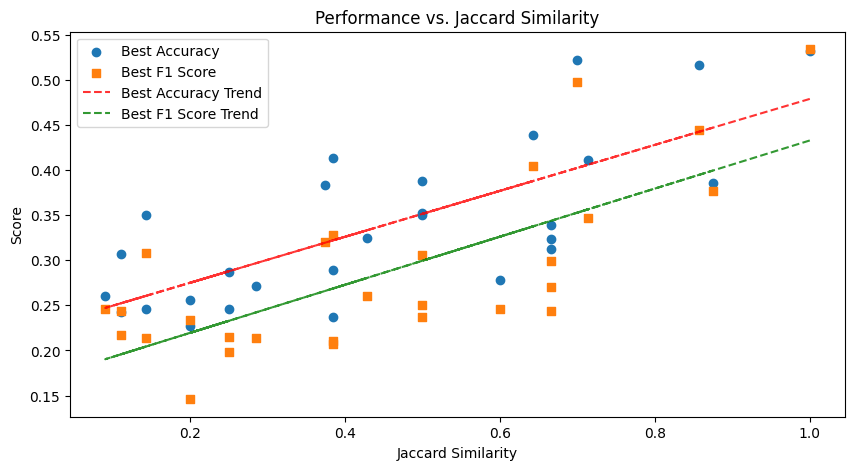

R2 correlation coefficient for Best Accuracy: 0.1849
R2 correlation coefficient for Best F1 Score: 0.5415


In [ ]:
results_experiment_0 = pd.read_csv("results_experiment_0.csv")
plt.figure(figsize=(10, 5))
# Plot Accuracy AND f1-score against jaccard similarity + Best fit line for both metrics
plt.scatter(results_experiment_0["Jaccard Similarity"], results_experiment_0["Best Accuracy"], marker='o', label='Best Accuracy')
plt.scatter(results_experiment_0["Jaccard Similarity"], results_experiment_0["Best F1 Score"], marker='s', label='Best F1 Score')

# Add best fit lines and report R2 correlation coefficient
z = np.polyfit(results_experiment_0["Jaccard Similarity"], results_experiment_0["Best Accuracy"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_0["Jaccard Similarity"], p(results_experiment_0["Jaccard Similarity"]), "r--", alpha=0.8, label="Best Accuracy Trend")

z = np.polyfit(results_experiment_0["Jaccard Similarity"], results_experiment_0["Best F1 Score"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_0["Jaccard Similarity"], p(results_experiment_0["Jaccard Similarity"]), "g--", alpha=0.8, label="Best F1 Score Trend")

# Calculate R2 correlation coefficients
r2_accuracy = r2_score(results_experiment_0["Best Accuracy"], p(results_experiment_0["Jaccard Similarity"]))
r2_f1 = r2_score(results_experiment_0["Best F1 Score"], p(results_experiment_0["Jaccard Similarity"]))


plt.xlabel("Jaccard Similarity")
plt.ylabel("Score")
plt.title("Logistic Regression: Performance vs. Jaccard Similarity")
plt.legend()
plt.show()
print(f"R2 correlation coefficient for Best Accuracy: {r2_accuracy:.4f}")
print(f"R2 correlation coefficient for Best F1 Score: {r2_f1:.4f}")

## Experiment 1: MLP

In [ ]:

class MLPClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MLPClassifier, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x 


def train_mlp(
    train_loader, test_loader, model, criterion,
    optimizer, EPOCHS, checkpoint_path
):
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.1,
        patience=3
    )

    best_loss = float("inf")
    best_accuracy = 0.0
    best_f1_score = 0.0

    train_losses, val_losses = [], []
    accuracies, f1_scores = [], []

    for epoch in range(EPOCHS):

        # Training
        model.train()
        train_loss_sum = 0.0
        train_samples = 0

        for data, target in train_loader:
            data = data.to(device)
            target = target.to(device).long()

            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            n = target.size(0)
            train_loss_sum += loss.item() * n
            train_samples += n

        avg_train_loss = train_loss_sum / train_samples
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_samples = 0
        all_preds, all_targets = [], []

        with torch.no_grad():
            for data, target in test_loader:
                data = data.to(device)
                target = target.to(device).long()

                output = model(data)
                val_loss = criterion(output, target)

                n = target.size(0)
                val_loss_sum += val_loss.item() * n
                val_samples += n

                preds = output.argmax(dim=1)
                all_preds.extend(preds.cpu().tolist())
                all_targets.extend(target.cpu().tolist())

        avg_val_loss = val_loss_sum / val_samples

        accuracy = accuracy_score(all_targets, all_preds)
        macro_f1 = f1_score(
            all_targets, all_preds,
            average="macro", zero_division=0
        )

        val_losses.append(avg_val_loss)
        accuracies.append(accuracy)
        f1_scores.append(macro_f1)

        # Scheduler: once per epoch
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        # Save best model
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_accuracy = accuracy
            best_f1_score = macro_f1
            torch.save(model.state_dict(), checkpoint_path)

            print(f"Best MLP saved: val_loss={best_loss:.4f}")

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"LR: {current_lr:.6g}"
        )

    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }

    return results, best_accuracy, best_f1_score


In [26]:
def experiment_1():
    accs = []
    f1s = []
    similarity_scores = []
    for i in range(len(config_pairs)):
        train_config, test_config = config_pairs[i]
        similarity = jaccard_similarity(train_config, test_config)
        similarity_scores.append(similarity)
        INPUT_DIM = X_train.shape[1] + len(C0)  # Adjust for mask
        OUTPUT_DIM = len(np.unique(y_train))
        HIDDEN_DIM = 64
        BATCH_SIZE = 64
        LEARNING_RATE=GLOBAL_LEARNING_RATE
        EPOCHS=GLOBAL_EPOCHS

        model_1 = MLPClassifier(INPUT_DIM, HIDDEN_DIM,OUTPUT_DIM).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model_1.parameters(), lr=LEARNING_RATE)

        train_loader, test_loader = create_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, BATCH_SIZE)
        results, best_acc, best_f1_score = train_mlp(train_loader, test_loader, model_1, criterion, optimizer, EPOCHS, f"best_model.pth")
        accs.append(best_acc)
        f1s.append(best_f1_score)
    results_experiment_1 = pd.DataFrame({
        "Train Config": [f"C{i+1}" for i in range(len(config_pairs))],
        "Test Config": [f"C{i+2}" for i in range(len(config_pairs))],
        "Jaccard Similarity": similarity_scores,
        "Best Accuracy": accs,
        "Best F1 Score": f1s
    })
    return results_experiment_1

In [27]:
results_experiment_1 = experiment_1()
results_experiment_1.to_csv("results_experiment_1.csv", index=False)

Best MLP saved: val_loss=1.3408
Epoch 1/25 | Train Loss: 1.3645 | Val Loss: 1.3408 | Accuracy: 0.3485 | Macro F1: 0.2643 | LR: 0.001
Best MLP saved: val_loss=1.3054
Epoch 2/25 | Train Loss: 1.3224 | Val Loss: 1.3054 | Accuracy: 0.3846 | Macro F1: 0.3253 | LR: 0.001
Best MLP saved: val_loss=1.2748
Epoch 3/25 | Train Loss: 1.2891 | Val Loss: 1.2748 | Accuracy: 0.4135 | Macro F1: 0.3568 | LR: 0.001
Best MLP saved: val_loss=1.2472
Epoch 4/25 | Train Loss: 1.2594 | Val Loss: 1.2472 | Accuracy: 0.4237 | Macro F1: 0.3763 | LR: 0.001
Best MLP saved: val_loss=1.2216
Epoch 5/25 | Train Loss: 1.2324 | Val Loss: 1.2216 | Accuracy: 0.4443 | Macro F1: 0.4026 | LR: 0.001
Best MLP saved: val_loss=1.1973
Epoch 6/25 | Train Loss: 1.2071 | Val Loss: 1.1973 | Accuracy: 0.4569 | Macro F1: 0.4112 | LR: 0.001
Best MLP saved: val_loss=1.1741
Epoch 7/25 | Train Loss: 1.1832 | Val Loss: 1.1741 | Accuracy: 0.4672 | Macro F1: 0.4303 | LR: 0.001
Best MLP saved: val_loss=1.1512
Epoch 8/25 | Train Loss: 1.1600 | Val

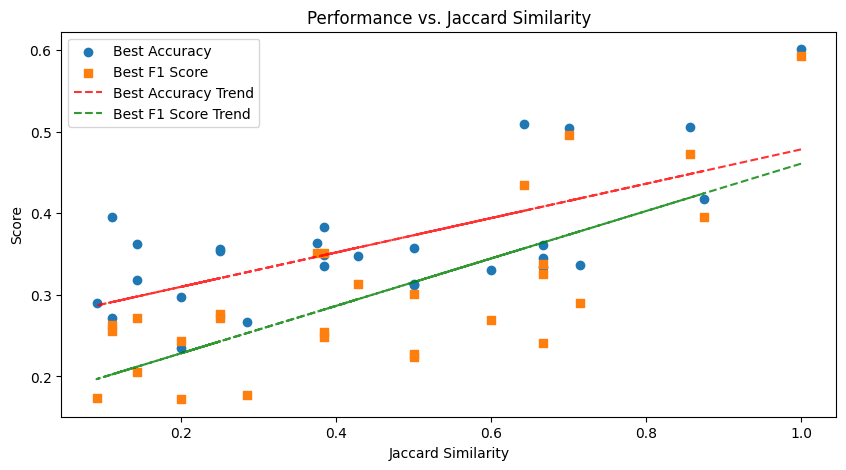

R2 correlation coefficient for Best Accuracy: -0.2126
R2 correlation coefficient for Best F1 Score: 0.5501


In [ ]:
results_experiment_1 = pd.read_csv("results_experiment_1.csv")
plt.figure(figsize=(10, 5))
# Plot Accuracy AND f1-score against jaccard similarity + Best fit line for both metrics
plt.scatter(results_experiment_1["Jaccard Similarity"], results_experiment_1["Best Accuracy"], marker='o', label='Best Accuracy')
plt.scatter(results_experiment_1["Jaccard Similarity"], results_experiment_1["Best F1 Score"], marker='s', label='Best F1 Score')

# Add best fit lines and report R2 correlation coefficient
z = np.polyfit(results_experiment_1["Jaccard Similarity"], results_experiment_1["Best Accuracy"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_1["Jaccard Similarity"], p(results_experiment_1["Jaccard Similarity"]), "r--", alpha=0.8, label="Best Accuracy Trend")

z = np.polyfit(results_experiment_1["Jaccard Similarity"], results_experiment_1["Best F1 Score"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_1["Jaccard Similarity"], p(results_experiment_1["Jaccard Similarity"]), "g--", alpha=0.8, label="Best F1 Score Trend")

# Calculate R2 correlation coefficients
r2_accuracy = r2_score(results_experiment_1["Best Accuracy"], p(results_experiment_1["Jaccard Similarity"]))
r2_f1 = r2_score(results_experiment_1["Best F1 Score"], p(results_experiment_1["Jaccard Similarity"]))


plt.xlabel("Jaccard Similarity")
plt.ylabel("Score")
plt.title("MLP: Performance vs. Jaccard Similarity")
plt.legend()
plt.show()
print(f"R2 correlation coefficient for Best Accuracy: {r2_accuracy:.4f}")
print(f"R2 correlation coefficient for Best F1 Score: {r2_f1:.4f}")

## Deep Sets


In [33]:
def create_deepset_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, batch_size=64):
    train_config = np.asarray(train_config, dtype=bool)
    test_config = np.asarray(test_config, dtype=bool)

    X_train = X_train.copy()
    X_test = X_test.copy()
    y_train = y_train.copy()
    y_test = y_test.copy()

    X_train[:, ~train_config] = 0.0
    X_test[:, ~test_config] = 0.0

    train_mask = np.tile(
        train_config.astype(np.float32),
        (len(X_train), 1)
    )
    test_mask = np.tile(
        test_config.astype(np.float32),
        (len(X_test), 1)
    )
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    train_mask = torch.tensor(train_mask, dtype=torch.float32)
    test_mask = torch.tensor(test_mask, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    train_dataset = TensorDataset(X_train, train_mask, y_train)
    test_dataset = TensorDataset(X_test, test_mask, y_test)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


In [34]:
class DeepSets(nn.Module):
    def __init__(self, num_features, embedding_dim, latent_dim, output_dim):
        super(DeepSets, self).__init__()

        self.feature_embedding = nn.Embedding(num_features, embedding_dim)
        self.phi = nn.Sequential(
            nn.Linear(embedding_dim+1, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU()
        )
        self.rho = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, output_dim)
        )
    def forward(self, x, mask):
        B, F = x.shape
        feature_ids = torch.arange(F, device=x.device).unsqueeze(0).expand(B, F)
        embedddings = self.feature_embedding(feature_ids)

        values = x.unsqueeze(-1)
        elements = torch.cat([embedddings, values], dim=-1)
        elements = self.phi(elements)
        elements = elements * mask.unsqueeze(-1)
        z = elements.sum(dim=1)
        logits = self.rho(z)
        return logits


In [35]:
def train_deepsets(
    train_loader, test_loader, model, criterion,
    optimizer, EPOCHS, checkpoint_path
):
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.1,
        patience=3
    )

    best_loss = float("inf")
    best_accuracy = 0.0
    best_f1_score = 0.0

    train_losses, val_losses = [], []
    accuracies, f1_scores = [], []

    for epoch in range(EPOCHS):

        # Training
        model.train()
        train_loss_sum = 0.0
        train_samples = 0

        for data, mask, target in train_loader:
            data = data.to(device)
            mask = mask.to(device)
            target = target.to(device).long()

            optimizer.zero_grad()
            output = model(data, mask)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            n = target.size(0)
            train_loss_sum += loss.item() * n
            train_samples += n

        avg_train_loss = train_loss_sum / train_samples
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_samples = 0
        all_preds, all_targets = [], []

        with torch.no_grad():
            for data, mask, target in test_loader:
                data = data.to(device)
                mask = mask.to(device)
                target = target.to(device).long()

                output = model(data, mask)
                val_loss = criterion(output, target)

                n = target.size(0)
                val_loss_sum += val_loss.item() * n
                val_samples += n

                preds = output.argmax(dim=1)
                all_preds.extend(preds.cpu().tolist())
                all_targets.extend(target.cpu().tolist())

        avg_val_loss = val_loss_sum / val_samples

        accuracy = accuracy_score(all_targets, all_preds)
        macro_f1 = f1_score(
            all_targets, all_preds,
            average="macro", zero_division=0
        )

        val_losses.append(avg_val_loss)
        accuracies.append(accuracy)
        f1_scores.append(macro_f1)

        # Scheduler: once per epoch
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        # Save best model
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_accuracy = accuracy
            best_f1_score = macro_f1
            torch.save(model.state_dict(), checkpoint_path)

            print(f"Best Deep Sets saved: val_loss={best_loss:.4f}")

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"LR: {current_lr:.6g}"
        )

    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }

    return results, best_accuracy, best_f1_score


In [36]:
def experiment_2():
    accs = []
    f1s = []
    similarity_scores = []
    for i in range(len(config_pairs)):
        train_config, test_config = config_pairs[i]
        similarity = jaccard_similarity(train_config, test_config)
        similarity_scores.append(similarity)
        NUM_FEATURES = X_train.shape[1] 
        OUTPUT_DIM = len(np.unique(y_train))
        LATENT_DIM = 64
        ELEMENT_DIM = 32
        BATCH_SIZE = 64 
        LEARNING_RATE=GLOBAL_LEARNING_RATE
        EPOCHS=GLOBAL_EPOCHS

        model_2 = DeepSets(NUM_FEATURES, ELEMENT_DIM, LATENT_DIM, OUTPUT_DIM).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model_2.parameters(), lr=LEARNING_RATE)

        train_loader, test_loader = create_deepset_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, BATCH_SIZE)
        results, best_acc, best_f1_score = train_deepsets(train_loader, test_loader, model_2, criterion, optimizer, EPOCHS, f"best_model.pth")
        accs.append(best_acc)
        f1s.append(best_f1_score)
    results_experiment_2 = pd.DataFrame({
        "Train Config": [f"C{i+1}" for i in range(len(config_pairs))],
        "Test Config": [f"C{i+2}" for i in range(len(config_pairs))],
        "Jaccard Similarity": similarity_scores,
        "Best Accuracy": accs,
        "Best F1 Score": f1s
    })
    return results_experiment_2


In [37]:
results_experiment_2 = experiment_2()
results_experiment_2.to_csv("results_experiment_2.csv", index=False)

Best Deep Sets saved: val_loss=1.3705
Epoch 1/25 | Train Loss: 1.3793 | Val Loss: 1.3705 | Accuracy: 0.2883 | Macro F1: 0.1119 | LR: 0.001
Best Deep Sets saved: val_loss=1.3666
Epoch 2/25 | Train Loss: 1.3695 | Val Loss: 1.3666 | Accuracy: 0.2892 | Macro F1: 0.1137 | LR: 0.001
Best Deep Sets saved: val_loss=1.3623
Epoch 3/25 | Train Loss: 1.3655 | Val Loss: 1.3623 | Accuracy: 0.3304 | Macro F1: 0.1796 | LR: 0.001
Best Deep Sets saved: val_loss=1.3574
Epoch 4/25 | Train Loss: 1.3608 | Val Loss: 1.3574 | Accuracy: 0.3054 | Macro F1: 0.1430 | LR: 0.001
Best Deep Sets saved: val_loss=1.3516
Epoch 5/25 | Train Loss: 1.3554 | Val Loss: 1.3516 | Accuracy: 0.3333 | Macro F1: 0.1828 | LR: 0.001
Best Deep Sets saved: val_loss=1.3438
Epoch 6/25 | Train Loss: 1.3486 | Val Loss: 1.3438 | Accuracy: 0.4067 | Macro F1: 0.2931 | LR: 0.001
Best Deep Sets saved: val_loss=1.3344
Epoch 7/25 | Train Loss: 1.3401 | Val Loss: 1.3344 | Accuracy: 0.3894 | Macro F1: 0.2788 | LR: 0.001
Best Deep Sets saved: val_l

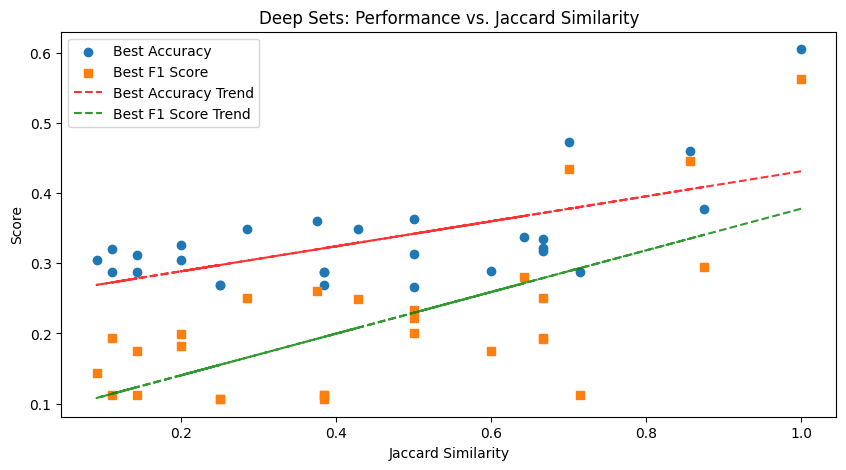

R2 correlation coefficient for Best Accuracy: -2.4853
R2 correlation coefficient for Best F1 Score: 0.4643


In [28]:
results_experiment_2 = pd.read_csv("results_experiment_2.csv")
plt.figure(figsize=(10, 5))
# Plot Accuracy AND f1-score against jaccard similarity + Best fit line for both metrics
plt.scatter(results_experiment_2["Jaccard Similarity"], results_experiment_2["Best Accuracy"], marker='o', label='Best Accuracy')
plt.scatter(results_experiment_2["Jaccard Similarity"], results_experiment_2["Best F1 Score"], marker='s', label='Best F1 Score')

# Add best fit lines and report R2 correlation coefficient
z = np.polyfit(results_experiment_2["Jaccard Similarity"], results_experiment_2["Best Accuracy"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_2["Jaccard Similarity"], p(results_experiment_2["Jaccard Similarity"]), "r--", alpha=0.8, label="Best Accuracy Trend")

z = np.polyfit(results_experiment_2["Jaccard Similarity"], results_experiment_2["Best F1 Score"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_2["Jaccard Similarity"], p(results_experiment_2["Jaccard Similarity"]), "g--", alpha=0.8, label="Best F1 Score Trend")

# Calculate R2 correlation coefficients
r2_accuracy = r2_score(results_experiment_2["Best Accuracy"], p(results_experiment_2["Jaccard Similarity"]))
r2_f1 = r2_score(results_experiment_2["Best F1 Score"], p(results_experiment_2["Jaccard Similarity"]))


plt.xlabel("Jaccard Similarity")
plt.ylabel("Score")
plt.title("Deep Sets: Performance vs. Jaccard Similarity")
plt.legend()
plt.show()
print(f"R2 correlation coefficient for Best Accuracy: {r2_accuracy:.4f}")
print(f"R2 correlation coefficient for Best F1 Score: {r2_f1:.4f}")

## Set Transformers

In [22]:
def create_deepset_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, batch_size=64):
    train_config = np.asarray(train_config, dtype=bool)
    test_config = np.asarray(test_config, dtype=bool)

    X_train = X_train.copy()
    X_test = X_test.copy()
    y_train = y_train.copy()
    y_test = y_test.copy()

    X_train[:, ~train_config] = 0.0
    X_test[:, ~test_config] = 0.0

    train_mask = np.tile(
        train_config.astype(np.float32),
        (len(X_train), 1)
    )
    test_mask = np.tile(
        test_config.astype(np.float32),
        (len(X_test), 1)
    )
    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)

    train_mask = torch.tensor(train_mask, dtype=torch.float32)
    test_mask = torch.tensor(test_mask, dtype=torch.float32)

    y_train = torch.tensor(y_train, dtype=torch.long)
    y_test = torch.tensor(y_test, dtype=torch.long)

    train_dataset = TensorDataset(X_train, train_mask, y_train)
    test_dataset = TensorDataset(X_test, test_mask, y_test)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


In [23]:
class SetTransformer(nn.Module):
    def __init__(self, num_features, embedding_dim, latent_dim, num_heads, output_dim):
        super().__init__()

        self.feature_embeddings = nn.Embedding(num_features, embedding_dim)
        self.input_projection = nn.Linear(embedding_dim+1, latent_dim)
        self.attention = nn.MultiheadAttention(embed_dim=latent_dim, num_heads=num_heads, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim)
        )
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, output_dim)
        )
    def forward(self, x, mask):
        B, F = x.shape
        feature_ids = torch.arange(F, device=x.device)
        feature_ids = feature_ids.unsqueeze(0).expand(B,F)
        embeddings = self.feature_embeddings(feature_ids)
        values = x.unsqueeze(-1)
        elements = torch.cat([embeddings,values], dim=-1)
        elements = self.input_projection(elements)
        elements = torch.relu(elements)
        attention_mask = mask == 0
        attended, _ = self.attention(elements, elements, elements, key_padding_mask=attention_mask)
        elements = elements + attended 
        elements = elements + self.ffn(elements)
        elements = elements * mask.unsqueeze(-1)
        z = elements.sum(dim=1)
        logits = self.classifier(z)
        return logits

In [24]:

def train_settransformer(
    train_loader, test_loader, model, criterion,
    optimizer, EPOCHS, checkpoint_path
):
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.1,
        patience=3
    )

    best_loss = float("inf")
    best_accuracy = 0.0
    best_f1_score = 0.0

    train_losses, val_losses = [], []
    accuracies, f1_scores = [], []

    for epoch in range(EPOCHS):

        # Training
        model.train()
        train_loss_sum = 0.0
        train_samples = 0

        for data, mask, target in train_loader:
            data = data.to(device)
            mask = mask.to(device)
            target = target.to(device).long()

            optimizer.zero_grad()
            output = model(data, mask)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            n = target.size(0)
            train_loss_sum += loss.item() * n
            train_samples += n

        avg_train_loss = train_loss_sum / train_samples
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        val_loss_sum = 0.0
        val_samples = 0
        all_preds, all_targets = [], []

        with torch.no_grad():
            for data, mask, target in test_loader:
                data = data.to(device)
                mask = mask.to(device)
                target = target.to(device).long()

                output = model(data, mask)
                val_loss = criterion(output, target)

                n = target.size(0)
                val_loss_sum += val_loss.item() * n
                val_samples += n

                preds = output.argmax(dim=1)
                all_preds.extend(preds.cpu().tolist())
                all_targets.extend(target.cpu().tolist())

        avg_val_loss = val_loss_sum / val_samples

        accuracy = accuracy_score(all_targets, all_preds)
        macro_f1 = f1_score(
            all_targets, all_preds,
            average="macro", zero_division=0
        )

        val_losses.append(avg_val_loss)
        accuracies.append(accuracy)
        f1_scores.append(macro_f1)

        # Scheduler: once per epoch
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        # Save best model
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_accuracy = accuracy
            best_f1_score = macro_f1
            torch.save(model.state_dict(), checkpoint_path)

            print(
                f"Best Set Transformer saved: "
                f"val_loss={best_loss:.4f}"
            )

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"LR: {current_lr:.6g}"
        )

    results = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "accuracies": accuracies,
        "f1_scores": f1_scores
    }

    return results, best_accuracy, best_f1_score


In [25]:

def experiment_3():
    accs = []
    f1s = []
    similarity_scores = []
    for i in range(len(config_pairs)):
        train_config, test_config = config_pairs[i]
        similarity = jaccard_similarity(train_config, test_config)
        similarity_scores.append(similarity)
        NUM_FEATURES = X_train.shape[1]
        EMBEDDING_DIM = 16
        LATENT_DIM = 64
        NUM_HEADS = 4
        OUTPUT_DIM = len(np.unique(y_train))
        LEARNING_RATE = GLOBAL_LEARNING_RATE
        EPOCHS = GLOBAL_EPOCHS
        BATCH_SIZE = 64
        model_3 = SetTransformer(num_features = NUM_FEATURES,
            embedding_dim=EMBEDDING_DIM,
            latent_dim=LATENT_DIM,
            num_heads = NUM_HEADS,
            output_dim = OUTPUT_DIM).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model_3.parameters(), lr=LEARNING_RATE)

        train_loader, test_loader = create_deepset_dataloaders(X_train, X_test, y_train, y_test, train_config, test_config, BATCH_SIZE)
        results, best_acc, best_f1_score = train_settransformer(train_loader, test_loader, model_3, criterion, optimizer, EPOCHS, f"best_model.pth")
        accs.append(best_acc)
        f1s.append(best_f1_score)
    results_experiment_3 = pd.DataFrame({
        "Train Config": [f"C{i+1}" for i in range(len(config_pairs))],
        "Test Config": [f"C{i+2}" for i in range(len(config_pairs))],
        "Jaccard Similarity": similarity_scores,
        "Best Accuracy": accs,
        "Best F1 Score": f1s
    })
    return results_experiment_3



In [26]:
results_experiment_3 = experiment_3()
results_experiment_3.to_csv("results_experiment_3.csv", index=False)

Best Set Transformer saved: val_loss=1.3234
Epoch 12/25 | Train Loss: 1.3027 | Val Loss: 1.3234 | Accuracy: 0.3589 | Macro F1: 0.2259 | LR: 0.001
Best Set Transformer saved: val_loss=1.3206
Epoch 13/25 | Train Loss: 1.2949 | Val Loss: 1.3206 | Accuracy: 0.3654 | Macro F1: 0.2615 | LR: 0.001
Best Set Transformer saved: val_loss=1.3102
Epoch 14/25 | Train Loss: 1.2869 | Val Loss: 1.3102 | Accuracy: 0.3727 | Macro F1: 0.2753 | LR: 0.001
Best Set Transformer saved: val_loss=1.3075
Epoch 15/25 | Train Loss: 1.2788 | Val Loss: 1.3075 | Accuracy: 0.3713 | Macro F1: 0.2707 | LR: 0.001
Epoch 16/25 | Train Loss: 1.2701 | Val Loss: 1.3104 | Accuracy: 0.3685 | Macro F1: 0.2919 | LR: 0.001
Best Set Transformer saved: val_loss=1.3072
Epoch 17/25 | Train Loss: 1.2613 | Val Loss: 1.3072 | Accuracy: 0.3663 | Macro F1: 0.2884 | LR: 0.001
Best Set Transformer saved: val_loss=1.2950
Epoch 18/25 | Train Loss: 1.2519 | Val Loss: 1.2950 | Accuracy: 0.3702 | Macro F1: 0.3110 | LR: 0.001
Epoch 19/25 | Train Lo

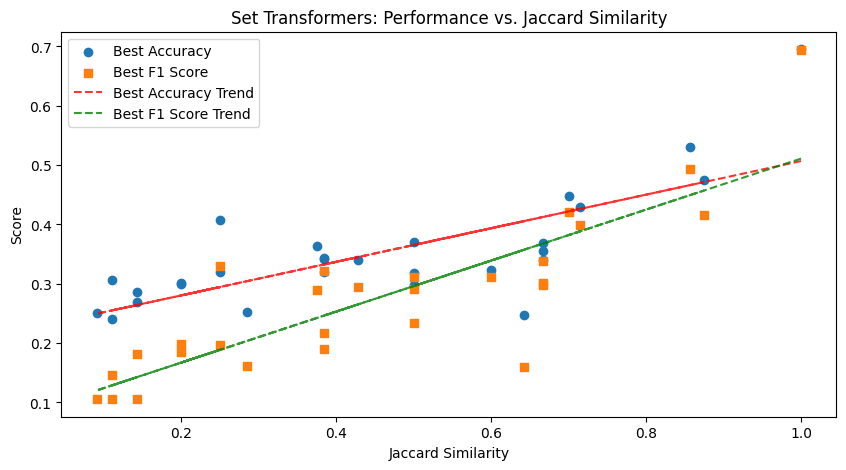

R2 correlation coefficient for Best Accuracy: -0.2319
R2 correlation coefficient for Best F1 Score: 0.7124


In [27]:
results_experiment_3 = pd.read_csv("results_experiment_3.csv")
plt.figure(figsize=(10, 5))
# Plot Accuracy AND f1-score against jaccard similarity + Best fit line for both metrics
plt.scatter(results_experiment_3["Jaccard Similarity"], results_experiment_3["Best Accuracy"], marker='o', label='Best Accuracy')
plt.scatter(results_experiment_3["Jaccard Similarity"], results_experiment_3["Best F1 Score"], marker='s', label='Best F1 Score')

# Add best fit lines and report R2 correlation coefficient
z = np.polyfit(results_experiment_3["Jaccard Similarity"], results_experiment_3["Best Accuracy"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_3["Jaccard Similarity"], p(results_experiment_3["Jaccard Similarity"]), "r--", alpha=0.8, label="Best Accuracy Trend")

z = np.polyfit(results_experiment_3["Jaccard Similarity"], results_experiment_3["Best F1 Score"], 1)
p = np.poly1d(z)
plt.plot(results_experiment_3["Jaccard Similarity"], p(results_experiment_3["Jaccard Similarity"]), "g--", alpha=0.8, label="Best F1 Score Trend")

# Calculate R2 correlation coefficients
r2_accuracy = r2_score(results_experiment_3["Best Accuracy"], p(results_experiment_3["Jaccard Similarity"]))
r2_f1 = r2_score(results_experiment_3["Best F1 Score"], p(results_experiment_3["Jaccard Similarity"]))


plt.xlabel("Jaccard Similarity")
plt.ylabel("Score")
plt.title("Set Transformers: Performance vs. Jaccard Similarity")
plt.legend()
plt.show()
print(f"R2 correlation coefficient for Best Accuracy: {r2_accuracy:.4f}")
print(f"R2 correlation coefficient for Best F1 Score: {r2_f1:.4f}")

## Analysis

In [7]:
results_experiment_0 = pd.read_csv("results_experiment_0.csv")
results_experiment_1 = pd.read_csv("results_experiment_1.csv")
results_experiment_2 = pd.read_csv("results_experiment_2.csv")
results_experiment_3 = pd.read_csv("results_experiment_3.csv")


results_experiment_0["Model"] = "LR"
results_experiment_1["Model"] = "MLP"
results_experiment_2["Model"] = "Deep Sets"
results_experiment_3["Model"] = "Set Transformer"


all_results = pd.concat(
    [
        results_experiment_0,
        results_experiment_1,
        results_experiment_2,
        results_experiment_3
    ],
    ignore_index=True
)

# Create a unique identifier for each train/test pair
all_results["Pair"] = (
    all_results["Train Config"].astype(str)
    + "->"
    + all_results["Test Config"].astype(str)
)

print(all_results.head())

  Train Config Test Config  Jaccard Similarity  Best Accuracy  Best F1 Score  \
0           C1          C2            1.000000       0.531786       0.533828   
1           C2          C3            0.142857       0.246071       0.214197   
2           C3          C4            0.111111       0.306518       0.216796   
3           C4          C5            0.142857       0.349821       0.307712   
4           C5          C6            0.090909       0.259911       0.245783   

  Model    Pair  
0    LR  C1->C2  
1    LR  C2->C3  
2    LR  C3->C4  
3    LR  C4->C5  
4    LR  C5->C6  


In [8]:
from scipy.stats import spearmanr



# Table of rho and p value for All Models (LR, MLP, Deep Sets) for Jaccard Similarity vs. Best F1 Score
for model in all_results["Model"].unique():
    rho, p_value = spearmanr(
        all_results[all_results["Model"] == model]["Jaccard Similarity"],
        all_results[all_results["Model"] == model]["Best F1 Score"]
    )
    print(f"Model: {model}")
    print(f"Spearman rho: {rho:.3f}")
    print(f"p-value: {p_value:.4f}")
    print("-" * 30)

Model: LR
Spearman rho: 0.643
p-value: 0.0002
------------------------------
Model: MLP
Spearman rho: 0.631
p-value: 0.0003
------------------------------
Model: Deep Sets
Spearman rho: 0.576
p-value: 0.0013
------------------------------
Model: Set Transformer
Spearman rho: 0.828
p-value: 0.0000
------------------------------


In [9]:
from scipy.stats import spearmanr



# Table of rho and p value for All Models (LR, MLP, Deep Sets) for Jaccard Similarity vs. Best F1 Score
for model in all_results["Model"].unique():
    rho, p_value = spearmanr(
        all_results[all_results["Model"] == model]["Jaccard Similarity"],
        all_results[all_results["Model"] == model]["Best Accuracy"]
    )
    print(f"Model: {model}")
    print(f"Spearman rho: {rho:.3f}")
    print(f"p-value: {p_value:.4f}")
    print("-" * 30)

Model: LR
Spearman rho: 0.707
p-value: 0.0000
------------------------------
Model: MLP
Spearman rho: 0.484
p-value: 0.0090
------------------------------
Model: Deep Sets
Spearman rho: 0.476
p-value: 0.0105
------------------------------
Model: Set Transformer
Spearman rho: 0.716
p-value: 0.0000
------------------------------


In [10]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    'Q("Best F1 Score") ~ '
    'Q("Jaccard Similarity") * '
    'C(Model, Treatment(reference="LR"))',
    data=all_results,
    groups=all_results["Pair"]
)

fit = model.fit()
print(fit.summary())

                                          Mixed Linear Model Regression Results
Model:                               MixedLM                    Dependent Variable:                    Q("Best F1 Score")
No. Observations:                    112                        Method:                                REML              
No. Groups:                          28                         Scale:                                 0.0029            
Min. group size:                     4                          Log-Likelihood:                        130.0974          
Max. group size:                     4                          Converged:                             Yes               
Mean group size:                     4.0                                                                                 
-------------------------------------------------------------------------------------------------------------------------
                                                                  

C:\Users\LOQ\AppData\Local\Temp\ipykernel_8612\3301452258.py:11: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = model.fit()


In [11]:
import statsmodels.formula.api as smf

model = smf.mixedlm(
    'Q("Best Accuracy") ~ '
    'Q("Jaccard Similarity") * '
    'C(Model, Treatment(reference="LR"))',
    data=all_results,
    groups=all_results["Pair"]
)

fit = model.fit()
print(fit.summary())

                                          Mixed Linear Model Regression Results
Model:                               MixedLM                    Dependent Variable:                    Q("Best Accuracy")
No. Observations:                    112                        Method:                                REML              
No. Groups:                          28                         Scale:                                 0.0018            
Min. group size:                     4                          Log-Likelihood:                        152.3936          
Max. group size:                     4                          Converged:                             Yes               
Mean group size:                     4.0                                                                                 
-------------------------------------------------------------------------------------------------------------------------
                                                                  

C:\Users\LOQ\AppData\Local\Temp\ipykernel_8612\2675987163.py:11: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = model.fit()


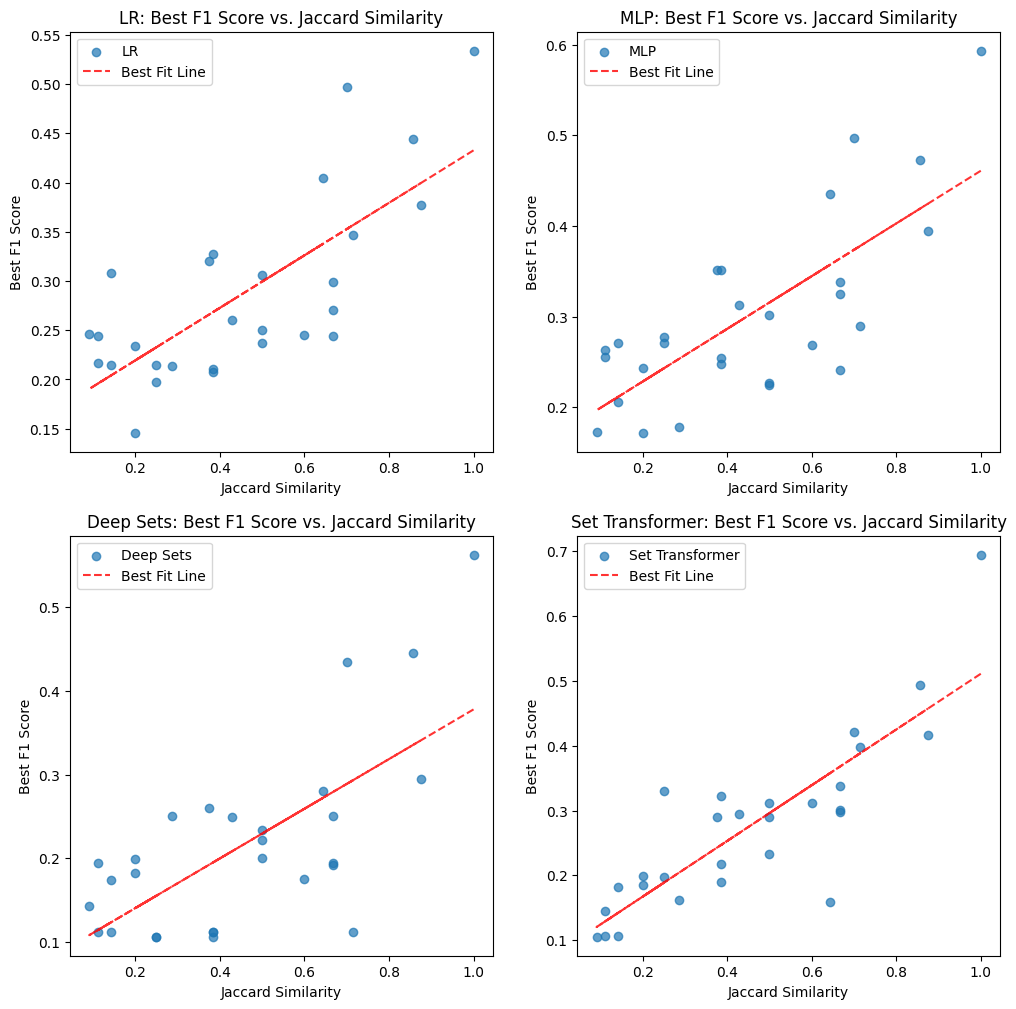

In [13]:
# Create a combined plot for all models showing Best F1 Score vs. Jaccard Similarity using subplots + best fit line 
plt.figure(figsize=(12, 12))
for i, model in enumerate(all_results["Model"].unique()):
    plt.subplot(2, 2, i + 1)
    model_data = all_results[all_results["Model"] == model]
    plt.scatter(
        model_data["Jaccard Similarity"],
        model_data["Best F1 Score"],
        label=model,
        alpha=0.7
    )
    z = np.polyfit(
        model_data["Jaccard Similarity"],
        model_data["Best F1 Score"],
        1
    )
    p = np.poly1d(z)
    plt.plot(
        model_data["Jaccard Similarity"],
        p(model_data["Jaccard Similarity"]),
        "r--",
        alpha=0.8,
        label="Best Fit Line"
    )
    plt.title(f"{model}: Best F1 Score vs. Jaccard Similarity")
    plt.xlabel("Jaccard Similarity")
    plt.ylabel("Best F1 Score")
    plt.legend()

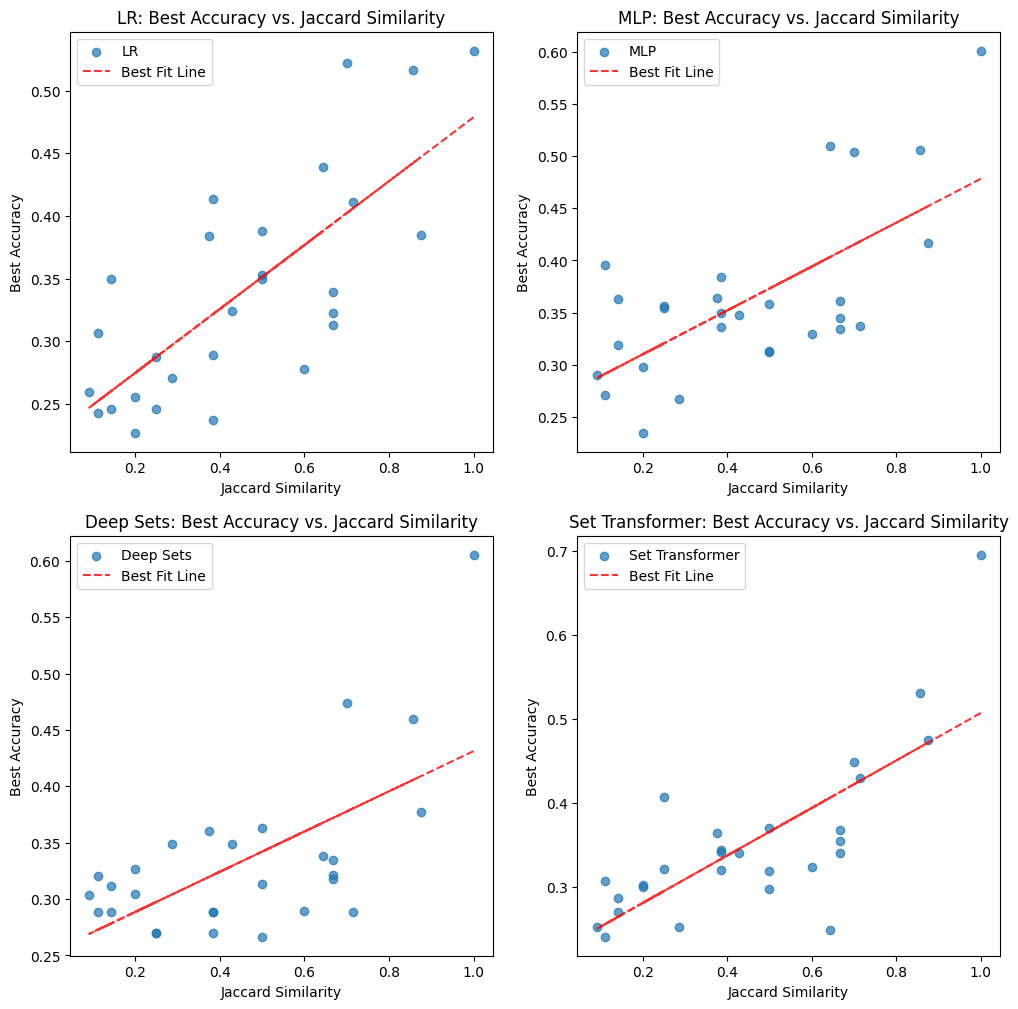

In [14]:
# Create a combined plot for all models showing Best Accuracy Score vs. Jaccard Similarity using subplots + best fit line 
plt.figure(figsize=(12, 12))
for i, model in enumerate(all_results["Model"].unique()):
    plt.subplot(2, 2, i + 1)
    model_data = all_results[all_results["Model"] == model]
    plt.scatter(
        model_data["Jaccard Similarity"],
        model_data["Best Accuracy"],
        label=model,
        alpha=0.7
    )
    z = np.polyfit(
        model_data["Jaccard Similarity"],
        model_data["Best Accuracy"],
        1
    )
    p = np.poly1d(z)
    plt.plot(
        model_data["Jaccard Similarity"],
        p(model_data["Jaccard Similarity"]),
        "r--",
        alpha=0.8,
        label="Best Fit Line"
    )
    plt.title(f"{model}: Best Accuracy vs. Jaccard Similarity")
    plt.xlabel("Jaccard Similarity")
    plt.ylabel("Best Accuracy")
    plt.legend()